#  <span style="color:#C133FF"> Processing MRI data for $\chi$ -fitting project!</span> 

In [1]:
import nibabel as nib
import numpy as np
import matplotlib.pyplot as plt
import sys
import pandas as pd
import os
import json
import time

#  <span style="color:#FA3F14"> Processing T1w for simulation</span> 

The first step is to combine the multiple FOVs with Slicer3D

###  <span style="color:#FAF614"> Compact Total Spine Seg output</span> 
After creation of the T1w whole body MRI through stitching, we can run the command

'sct_deepseg spine -i  t1w_wholebody.nii.gz -o totalspineseg.nii.gz'

There will be X amount of outputs and we take the path to totaspineseg_totalspineseg_all.nii.gz and merge the labels into their susceptibility groups

In [2]:
# 
bones = [3,4,5,6,7,17,18,19,20,21,22,23,24,25,35,36,37,38,39,40,41,42,43,44]
cartilage = [8,9,10,11,12,26,27,28,29,30,31,32,33,34,45,46,47,48,49,50,51,52,53]

spinal_structures = [1, 2] # Cord and canal

# List for all bones of the spine
vertebrae = [
    11, 12, 13, 14, 15, 16, 17, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 
    31, 32, 41, 42, 43, 44, 45, 50
]

# List for all the intervertebral discs
discs = [
    63, 64, 65, 66, 67, 71, 72, 73, 74, 75, 76, 77, 78, 79, 80, 81, 82, 
    91, 92, 93, 94, 95, 100
]

In [3]:
path_to_spineseg = r"R:\soothsayer\msc_data\chi_fitting\chi_028\niftis\t1w\slicer\sub-17_wb_t1w_totalspineseg_all.nii.gz"
spineseg_og_img = nib.load(path_to_spineseg)
spineseg_og_data = spineseg_og_img.get_fdata()
spineseg_og_data.shape

(291, 257, 595)

In [4]:
Size_X=(spineseg_og_data.shape)[0]
Size_Y=(spineseg_og_data.shape)[1]
Size_Z=(spineseg_og_data.shape)[2]

spine_seg_grouped = np.zeros((Size_X,Size_Y,Size_Z))

for i in range(len(spineseg_og_data[:,0,0])):
    for j in range( len(spineseg_og_data[0,:,0])):
        for k in range( len(spineseg_og_data[0,0,:])):

            pixel = spineseg_og_data[i,j,k]

            if pixel in spinal_structures: 
                spine_seg_grouped[i,j,k] = 10 # Spinal cord

            if pixel in vertebrae: 
                spine_seg_grouped[i,j,k]  = 11 # Bones

            if pixel in discs: 
                spine_seg_grouped[i,j,k]  = 12 # Discs

The numbers above don't matter because they will get re-ordered when creating the final whole body phantom with slicer

In [5]:
grouped_spineseg_img = nib.Nifti1Image(spine_seg_grouped, spineseg_og_img.affine)

path_to_spineseg_merged_output =  r"R:\soothsayer\msc_data\chi_fitting\chi_028\niftis\t1w\slicer\t1w_wholebody_merged_totalspineseg_all.nii.gz"

nib.save(grouped_spineseg_img, path_to_spineseg_merged_output)

###  <span style="color:#FAF614"> Compact Samseg output</span> 

On a similar note, SAMSEG will provide several regions of the brain, for now we can merge them to 1 individual brain label. Furthemore, this provides the skull label.

In [6]:
path_to_samseg_segs = r"R:\soothsayer\msc_data\chi_fitting\chi_028\niftis\t1w\initial_samseg_chi_028.nii.gz"
samseg_img = nib.load(path_to_samseg_segs)
samseg_data = np.array(samseg_img.get_fdata())
samseg_data.shape

(192, 260, 320)

In [7]:
# Check the numbers, this might change with new releases
# Last updated for Samseg under freesurfer 8.0.0-beta
samseg_brain_list = [2,3,4,5,7,8,10,11,12,13,14,15,16,17,18,24,26,28,30,31,41,42,43,44,46,47,49,50,51,52,53,54,58,60,62,63,72,77,80,85] #16 is the brainstem
samseg_skull_list = [165]

Size_X=(samseg_data.shape)[0]
Size_Y=(samseg_data.shape)[1]
Size_Z=(samseg_data.shape)[2]

grouped_samseg_data = np.zeros((Size_X,Size_Y,Size_Z))

for i in range(len(samseg_data[:,0,0])):
    for j in range( len(samseg_data[0,:,0])):
        for k in range( len(samseg_data[0,0,:])):

            pixel = samseg_data[i,j,k]
            
            if pixel in samseg_brain_list:
                grouped_samseg_data[i,j,k] = 23
            if pixel in samseg_skull_list:
                grouped_samseg_data[i,j,k] = 25

In [8]:
grouped_samseg_img = nib.Nifti1Image(grouped_samseg_data, samseg_img.affine)
out_path = r"R:\soothsayer\msc_data\chi_fitting\chi_028\niftis\t1w\brain_grouped_seg.nii.gz"
nib.save(grouped_samseg_img, out_path)

###  <span style="color:#FAF614"> Body and air segmentation with custom nnUNetv2</span> 

The initial segmentation of the trachea, lungs, and the body labels is done with a custom nnUNet

You must follow install instructions from nnUNetv2 first: <link>

Once that is done, follow this instructions to set up the trained model (you will need access to the trained model)

Activate the environment and run:

nnUNetv2_predict -i nnunet_input -c 3d_fullres -d 412 -tr nnUNetTrainerFT -p custom_plans730 -f 0 -o nnunet_output

###  <span style="color:#FAF614"> Combining all labels -> Define head-to-thorso phantom </span> 

Once all previous segmentations are finished, we can load them all up in slicer and combine them.

It is crucial to use "Logical Operators" under Segment editor, we need to remove overlap between labels, for example: the body label will overlap with the spinal cord, spinal canal, vertebrae and discs.

Once all overlap is corrected you would have: brain, skull, sinus, ear canal, trachea, vertebra, inter-vert. discs, spinal cord, two lungs, and body labels.

This now need to be sorted into the CANONICAL IDs used with tissue-to-MR-property

The order in which the labels appear in the final slicer output will depend on the actual order of the segmentations, in the following code cell you'll find the if statements where you need to change the if pixel according to what your segmentation file has, for example, for you the Body label could be #6, then you would change that to 6, the assignment of the new pixel value uses the CANONICAL IDs (version XXXX)

In [ ]:
final_labels_img = nib.load(r"R:\soothsayer\msc_data\chi_fitting\chi_027\niftis\t1w\final_all_labels.nii.gz")
final_samseg_data = final_labels_img.get_fdata()

Size_X=(final_samseg_data.shape)[0]
Size_Y=(final_samseg_data.shape)[1]
Size_Z=(final_samseg_data.shape)[2]

final_segmentations_converter = np.zeros((Size_X,Size_Y,Size_Z))

for i in range(len(final_samseg_data[:,0,0])):
    for j in range( len(final_samseg_data[0,:,0])):
        for k in range( len(final_samseg_data[0,0,:])):

            pixel = final_samseg_data[i,j,k]
            final_pixel = final_segmentations_converter[i,j,k]

            if pixel == 1: # Body label
                final_segmentations_converter[i,j,k] = 264

            if pixel == 8: # Bone from skull 
                final_segmentations_converter[i,j,k] = 10

            if pixel == 10: # Bone from spine 
                final_segmentations_converter[i,j,k] = 11

            if pixel == 2 or pixel == 3: # Lungs 1 & 2
                final_segmentations_converter[i,j,k] = 12

            if pixel == 6: # Sinus
                final_segmentations_converter[i,j,k] = 117

            if pixel == 5: # Ear canal
                final_segmentations_converter[i,j,k] = 119

            if pixel == 7: # Brain
                final_segmentations_converter[i,j,k] = 5

            if pixel == 4: # Trachea
                final_segmentations_converter[i,j,k] = 113

            if pixel == 11: # Intervertebral disc
                final_segmentations_converter[i,j,k] = 7

            if pixel == 9: # Spinal cord
                final_segmentations_converter[i,j,k] = 14

final_segmentations_converter_img =  nib.Nifti1Image(final_segmentations_converter, final_labels_img.affine)
nib.save(final_segmentations_converter_img, r"R:\soothsayer\msc_data\chi_fitting\chi_027\niftis\t1w/final_sorted_all_labels.nii.gz")   

###  <span style="color:#FAF614"> Sorted labels -> Chi-map -> Simulated FM</span> 

The following steps require using two CLI developed by our lab.

The first is move from label to susceptibility values based on literature (https://github.com/shimming-toolbox/tissue-to-MRproperty/tree/main)
-> Using version X

Command:
tissue_to_mr -i sorted_all_labels.nii.gz -t sus -o chimap_fn.nii.gz

The second is for simulating the field from the susceptibility distribution (https://github.com/shimming-toolbox/susceptibility-to-fieldmap-fft/tree/main)
-> Using version Y

Command:
compute_fieldmap -i chimap_fn.nii.gz -o fm_sim_custom.nii.gz -b x_dim y_dim z_dim -m constant 

Note that here we are providing a custom padding (default is 50,50,50) which makes the process VERY RAM hungry!

*This finishes the T1w section of the code*

#  <span style="color:#FA3F14"> Processing meGRE for in vivo B0 measurement and compare to initial simulation</span> 
You will have meGRE data that needs to first be concatenated and then the following steps are ran:
1. Using the first echo, run sct_deepseg spinalcord and sct_deepseg spine -> This will provide us with the SC mask and the discs file for later vertebral labelling
2. Run sct_label_vertebrae with the -s sc_mask -discfile disc.nii.gz -ofolder label_vert
3. Using the concatenated echoes we can calculate B0 with: julia c:/romeo/romeo.jl -p sub-16_part-phase_INSP_GRE.nii.gz -m sub-16_part-mag_INSP_GRE.nii.gz -B -Q -t [3.25, 5.22, 7.19] -o fm_tests  <- Note here we are hardcoding the path to ROMEO, using sub-16 as example, and echo times may vary depending on your acquisition protocol.
4. Extract metrics using the labelled SC mask for all labels
5. Define isocenter and select the range of vertebral levels that fit inside a 30-40 cm spehre around isocenter

In [27]:
participant_ID="Chi_028"

In [9]:
nifti_path = r"R:\soothsayer\msc_data\chi_fitting\chi_028\niftis\meGRE_INSP\raw_mag\sub-17_clearswi_gre_INSP_30_e1.nii.gz"
json_path = r"R:\soothsayer\msc_data\chi_fitting\chi_028\niftis\meGRE_INSP\raw_mag\sub-17_clearswi_gre_INSP_30_e1.json"

with open(json_path, "r") as f:
    metadata = json.load(f)

image = nib.load(nifti_path)

if metadata["Manufacturer"].lower() != "siemens":
    raise ValueError("This calculation was validated only for this Siemens case")

if metadata["PatientPosition"] != "HFS":
    raise ValueError(
        "This calculation was validated only for HFS positioning"
    )

table_position = np.asarray(metadata["TablePosition"], dtype=float)

if table_position.shape != (3,):
    raise ValueError("Expected a three-element Siemens TablePosition")

isocenter_ras = -table_position

isocenter_voxel = nib.affines.apply_affine(
    np.linalg.inv(image.affine),
    isocenter_ras,
)

inside_image = np.all(isocenter_voxel >= 0) and np.all(
    isocenter_voxel < np.asarray(image.shape[:3])
)

print("Isocenter RAS, mm:", isocenter_ras)
print("Isocenter voxel, zero-based:", isocenter_voxel)
print("Nearest voxel:", np.rint(isocenter_voxel).astype(int))
print("Inside image:", inside_image)

Isocenter RAS, mm: [  -0.   -0. -124.]
Isocenter voxel, zero-based: [56.13775486 63.07421875 11.21295884]
Nearest voxel: [56 63 11]
Inside image: True


### <span style="color:green"> Expiration B0 map </span> 



In [10]:
path_to_exp_B0_meas = r"R:\soothsayer\msc_data\chi_fitting\chi_028\niftis\meGRE_EXP\fm_tests\B0.nii"
path_to_exp_sc_msk = r"R:\soothsayer\msc_data\chi_fitting\chi_028\niftis\meGRE_EXP\raw_mag\sub-17_clearswi_gre_EXP_25_e1_seg.nii.gz"
path_to_exp_metric_msk = r"R:\soothsayer\msc_data\chi_fitting\chi_028\niftis\meGRE_EXP\label_vert\sub-17_clearswi_gre_EXP_25_e1_seg_labeled.nii.gz"

In [11]:
exp_B0_meas_img = nib.load(path_to_exp_B0_meas)
exp_B0_meas_data = exp_B0_meas_img.get_fdata()

exp_dmod_mask_img = nib.load(path_to_exp_sc_msk)
exp_dmod_mask_data = exp_dmod_mask_img.get_fdata()

exp_metric_mask_img = nib.load(path_to_exp_metric_msk)
exp_metric_mask_data = exp_metric_mask_img.get_fdata()

In [12]:
selected_exp_dmod_mask = np.isin(
    exp_metric_mask_data,
    range(2, 15),
)

In [13]:
exp_dmod_value = np.mean(exp_B0_meas_data[selected_exp_dmod_mask==1])
print("Expiration demod value: ",exp_dmod_value," Hz")

Expiration demod value:  219.96995520518877  Hz


In [15]:
raw_exp_B0_meas_csv = r"R:\soothsayer\msc_data\chi_fitting\chi_028\niftis\meGRE_EXP\sub-17_EXP_raw_b0_perlevel.csv"
raw_exp_metrics_df = pd.read_csv(raw_exp_B0_meas_csv)

exp_metrics_df = (
    raw_exp_metrics_df
    .loc[
        raw_exp_metrics_df["VertLevel"].between(
            2,
            14,
            inclusive="both",
        )
    ]
    .sort_values("VertLevel")
    .reset_index(drop=True)
)


raw_exp_metrics_data = exp_metrics_df['WA()']
raw_exp_metrics_data

0     202.200647
1     163.164894
2     126.414653
3     146.326057
4     204.564375
5     277.895225
6     354.787493
7     343.793342
8     263.210547
9     218.179247
10    206.604411
11    207.000397
12    201.535302
Name: WA(), dtype: float64

In [16]:
demod_exp_metrics_data = raw_exp_metrics_data - exp_dmod_value
demod_exp_metrics_data

0     -17.769308
1     -56.805061
2     -93.555302
3     -73.643899
4     -15.405580
5      57.925270
6     134.817538
7     123.823387
8      43.240592
9      -1.790708
10    -13.365544
11    -12.969558
12    -18.434653
Name: WA(), dtype: float64

In [17]:
# Export demodulated metrics to CSV
demod_exp_metrics_data.to_csv(
    r"R:\soothsayer\msc_data\chi_fitting\chi_028\niftis\meGRE_EXP\sub-17_DEMOD_EXP_b0_perlevel_1_15.csv",
    index=False,
    header=["dmod_B0_Hz"],
)

### <span style="color:red"> Inspiration B0 map </span> 

In [18]:
path_to_insp_B0_meas = r"R:\soothsayer\msc_data\chi_fitting\chi_028\niftis\meGRE_INSP\fm_tests\B0.nii"
path_to_insp_sc_msk = r"R:\soothsayer\msc_data\chi_fitting\chi_028\niftis\meGRE_INSP\raw_mag\sub-17_clearswi_gre_INSP_30_e1_seg.nii.gz"
path_to_insp_metric_msk = r"R:\soothsayer\msc_data\chi_fitting\chi_028\niftis\meGRE_INSP\label_vert\sub-17_clearswi_gre_INSP_30_e1_seg_labeled.nii.gz"

In [19]:
# Load images and get nifti data to manipulate!
insp_B0_meas_img = nib.load(path_to_insp_B0_meas)
insp_B0_meas_data = insp_B0_meas_img.get_fdata()

insp_dmod_mask_img = nib.load(path_to_insp_sc_msk)
insp_dmod_mask_data = insp_dmod_mask_img.get_fdata()

insp_metric_mask_img = nib.load(path_to_insp_metric_msk)
insp_metric_mask_data = insp_metric_mask_img.get_fdata()

In [20]:
selected_insp_dmod_mask = np.isin(
    insp_metric_mask_data,
    range(2, 15),
)

In [21]:
insp_dmod_value = np.mean(insp_B0_meas_data[selected_insp_dmod_mask==1])
print("Inspiration demod value: ", insp_dmod_value," Hz")

Inspiration demod value:  -310.3991734395185  Hz


In [22]:
raw_insp_B0_metrics_path = r"R:\soothsayer\msc_data\chi_fitting\chi_028\niftis\meGRE_INSP\sub-17_INSP_raw_b0_perlevel.csv"
raw_insp_metrics_df = pd.read_csv(raw_insp_B0_metrics_path)

insp_metrics_df = (
    raw_insp_metrics_df
    .loc[
        raw_insp_metrics_df["VertLevel"].between(
            2,
            14,
            inclusive="both",
        )
    ]
    .sort_values("VertLevel")
    .reset_index(drop=True)
)

raw_insp_metrics_data = insp_metrics_df['WA()']
raw_insp_metrics_data

0    -330.413683
1    -379.458744
2    -416.294092
3    -398.109719
4    -363.165796
5    -319.261291
6    -252.459340
7    -238.379663
8    -282.680097
9    -290.898186
10   -278.621041
11   -265.959158
12   -264.656398
Name: WA(), dtype: float64

In [23]:
dmod_insp_metrics_data = raw_insp_metrics_data - insp_dmod_value
dmod_insp_metrics_data

0     -20.014510
1     -69.059570
2    -105.894918
3     -87.710545
4     -52.766623
5      -8.862118
6      57.939834
7      72.019511
8      27.719076
9      19.500987
10     31.778132
11     44.440016
12     45.742776
Name: WA(), dtype: float64

In [24]:
# Export demodulated metrics to CSV
dmod_insp_metrics_data.to_csv(
    r"R:\soothsayer\msc_data\chi_fitting\chi_028\niftis\meGRE_INSP\sub-17_DEMOD_INSP_b0_perlevel_1_15.csv",
    index=False,
    header=["dmod_B0_Hz"],
)

### <span style="color:#C28AD1"> Average Insp and Exp metrics</span> 

In [25]:
demod_avg_respiration = (demod_exp_metrics_data+ dmod_insp_metrics_data )/2
demod_avg_respiration

0    -18.891909
1    -62.932316
2    -99.725110
3    -80.677222
4    -34.086101
5     24.531576
6     96.378686
7     97.921449
8     35.479834
9      8.855140
10     9.206294
11    15.735229
12    13.654062
Name: WA(), dtype: float64

In [26]:
vertebrae_levelsC2_T7 = ['C2','C3','C4', 'C5', 'C6', 'C7', 'T1', 'T2', 'T3', 'T4', 'T5', 'T6', 'T7'] # From 1 to 15

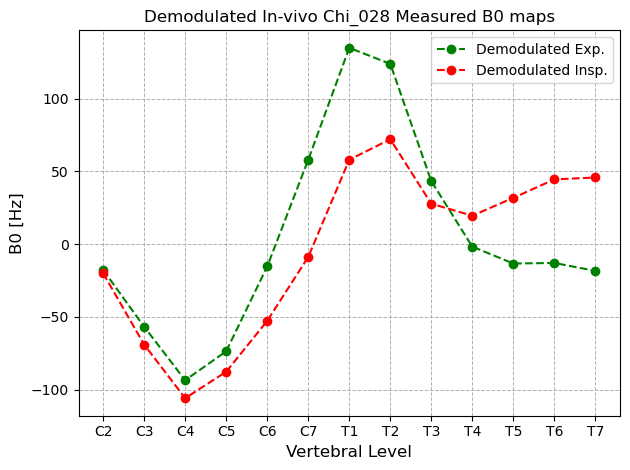

In [28]:
plt.plot(vertebrae_levelsC2_T7, demod_exp_metrics_data, marker = 'o', linestyle = '--', label = "Demodulated Exp.", color = "green")
plt.plot(vertebrae_levelsC2_T7, dmod_insp_metrics_data, marker = 'o', linestyle = '--', label = "Demodulated Insp.", color = "red")

plt.title(f"Demodulated In-vivo {participant_ID} Measured B0 maps")
plt.xlabel('Vertebral Level', fontsize=12)
plt.ylabel('B0 [Hz]', fontsize=12)
plt.legend()
# Customize grid and display
plt.grid(True, which='both', linestyle='--', linewidth=0.7)
plt.tight_layout()

# Show the plot
plt.show()

### <span style="color:#14EFFA"> Initial B0 simulation </span>

In [3]:
path_to_chi_to_fm_fft = r"C:\Users\Admin\Documents\msc_project\susceptibility-to-fieldmap-fft"
sys.path.append(path_to_chi_to_fm_fft)
from functions import compute_fieldmap

In [ ]:
path_to_dmod_msk = r""
path_to_chimap = r""
#
path_to_segs = r""
#
path_to_sim_metric_msk = r""
gamma_bar = 42.58 # MHz/T
B0 = 3 # [T]

central_freq_exp = 123.24928 # in MHz, the inspiration Central Frequency was: 123.248999 MHz
B0_used_scanner = central_freq_exp /gamma_bar
print("The B0 to use in the simulation should be: ", B0_used_scanner, "T")

chi_dist, image_res, affine_matrix = compute_fieldmap.load_sus_dist(path_to_chimap)
sim_chi_img = nib.load(path_to_chimap)
sim_chi_data = sim_chi_img.get_fdata()

# Load segmentation labels that create the chimaps
ROI_img = nib.load(path_to_segs)
ROI_data = ROI_img.get_fdata()

# Find indices with the labels we want to update
ind_trachea = np.where((ROI_data == 113))
ind_lungs = np.where((ROI_data == 12))

dmod_sim_mask = nib.load(path_to_dmod_msk).get_fdata()
metric_sim_mask = nib.load(path_to_sim_metric_msk).get_fdata()

vertebra_label_map = {"C1": 1, "C2": 2, "C3": 3, "C4": 4, "C5": 5, "C6": 6, "C7": 7, "T1": 8, "T2": 9, "T3": 10, "T4": 11, "T5": 12, "T6": 13, "T7": 14, "T8": 15}
vertebrae_levels_opt =  ['C2','C3','C4','C5','C6','C7','T1','T2','T3','T4','T5','T6','T7'] # From 2 to 14

The B0 to use in the simulation should be:  2.894526820103335 T


In [ ]:
raw_sim_B0_metrics_path = r""
raw_sim_metrics_df = pd.read_csv(raw_sim_B0_metrics_path)

sim_metrics_df = (
    raw_sim_metrics_df
    .loc[
        raw_sim_metrics_df["VertLevel"].between(
            2,
            14,
            inclusive="both",
        )
    ]
    .sort_values("VertLevel")
    .reset_index(drop=True)
)

raw_sim_metrics_data = sim_metrics_df['WA()']
raw_sim_metrics_data

0    -3.135291
1    -3.393058
2    -3.508121
3    -3.318102
4    -2.900417
5    -2.323972
6    -1.900564
7    -2.062070
8    -2.355388
9    -2.532803
10   -2.624520
11   -2.569185
12   -2.522302
Name: WA(), dtype: float64

In [6]:
# Now to go from ppm to Hz we can:
raw_sim_metrics_data_Hz = raw_sim_metrics_data * central_freq_exp # Because this is in MHz is same as doing * B0 * gamma_bar
raw_sim_metrics_data_Hz

0    -386.421281
1    -418.190793
2    -432.372237
3    -408.952594
4    -357.473393
5    -286.427113
6    -234.242571
7    -254.147929
8    -290.299152
9    -312.165352
10   -323.469376
11   -316.649359
12   -310.871078
Name: WA(), dtype: float64

In [7]:
selected_sim_dmod_mask = np.isin(
    metric_sim_mask,
    [
        vertebra_label_map[level]
        for level in vertebrae_levels_opt
    ],
).astype(np.uint8)

In [ ]:
initial_b0_data = nib.load(r"").get_fdata()
dmod_sim_value = np.mean(initial_b0_data[selected_sim_dmod_mask==1]) * central_freq_exp
dmod_sim_metrics_data_Hz = raw_sim_metrics_data_Hz - dmod_sim_value
dmod_sim_metrics_data_Hz

0     -47.908948
1     -79.678461
2     -93.859904
3     -70.440261
4     -18.961060
5      52.085219
6     104.269762
7      84.364403
8      48.213181
9      26.346980
10     15.042956
11     21.862974
12     27.641255
Name: WA(), dtype: float64

In [ ]:
# Export demodulated metrics to CSV
dmod_sim_metrics_data_Hz.to_csv(
    r"",
    index=False,
    header=["dmod_B0_Hz"],
)

#  <span style="color:#C133FF"> *Direct optimization!* </span> 

In [9]:
import importlib
import utils.tools as tools_module

In [10]:
importlib.reload(tools_module)

vertebral_response = (
    tools_module.vertebral_response
)

extract_demodulated_sc_profile = (
    tools_module.extract_demodulated_sc_profile
)

In [ ]:
# Careful! This needs to be thought before running the optimization
# This as well as the mode for doing the simulation with FFT based sim code
buffer_sim = (289, 260, 575)

In [ ]:
trachea_response = vertebral_response(
    roi_label=113,
    roi_data=ROI_data,
    image_res=image_res,
    central_freq=central_freq_exp,
    dmod_mask=selected_sim_dmod_mask,
    metric_mask=metric_sim_mask,
    vertebral_levels=vertebrae_levels_opt,
    vertebra_label_map=vertebra_label_map,
    buffer = buffer_sim,
    mode='constant'
)

lung_response = vertebral_response(
    roi_label=12,
    roi_data=ROI_data,
    image_res=image_res,
    central_freq=central_freq_exp,
    dmod_mask=selected_sim_dmod_mask,
    metric_mask=metric_sim_mask,
    vertebral_levels=vertebrae_levels_opt,
    vertebra_label_map=vertebra_label_map,
    buffer = buffer_sim,
    mode='constant'
)

label_names = {
    0: "External air",
    5: "Brain",
    7: "Intervertebral disc",
    9: "Skeletal muscle",
    10: "Skull",
    11: "Spine bone",
    12: "Lungs",
    14: "SC",
    113: "Trachea",
    117: "Sinus",
    119: "Ear canal",
    264: "Body",
}

In [30]:
lung_label = 12
trachea_label = 113

chi_trachea_fixed = 0.27

fixed_chi_map = sim_chi_data.copy()

# Here now, we remove the lung label
fixed_chi_map[ROI_data == lung_label] = 0.0
fixed_chi_map[ROI_data == trachea_label] = (
    chi_trachea_fixed
)

# Because the lung label is removed, we can now extract the demodulate SC profile without the lungs contribution and added after using chi_lung * lung_response !!
fixed_profile = extract_demodulated_sc_profile(
    chi_map=fixed_chi_map,
    image_res=image_res,
    central_freq=central_freq_exp,
    dmod_mask=selected_sim_dmod_mask,
    metric_mask=metric_sim_mask,
    vertebral_levels=vertebrae_levels_opt,
    vertebra_label_map=vertebra_label_map,
    buffer = buffer_sim,
    mode='constant'
)

In [35]:
# This is the participants measured profile!
# We can switch between average, exp and insp:
# demod_avg_respiration
# demod_exp_metrics_data
# dmod_insp_metrics_data
measured_profile = np.asarray(
    demod_avg_respiration,
    dtype=float,
)
measured_profile

array([-40.21077234, -72.53596008, -81.80094539, -58.15986596,
         3.22714819,  87.99065752, 121.14981303,  50.2639936 ,
        -1.69796014,  -4.90240521,  -1.42989954,  -3.70303575,
        -4.80986563])

In [36]:
# This tells us how much the the chi lung response needs to be to match the measured profile
target_for_lung = (
    measured_profile
    - fixed_profile
)

In [38]:
# Unconstrained analytical solution
chi_lung_unconstrained = (
    np.dot(
        lung_response,
        measured_profile - fixed_profile,
    )
    / np.dot(
        lung_response,
        lung_response,
    )
)

print(
    "Unconstrained lung susceptibility:",
    f"{chi_lung_unconstrained:.4f} ppm",
)

Unconstrained lung susceptibility: -0.5601 ppm


In [39]:
profile_unconstrained = (
    fixed_profile
    + chi_lung_unconstrained * lung_response
)

In [40]:
residual_unconstrained = (
    profile_unconstrained
    - measured_profile
)

rmse_unconstrained = np.sqrt(
    np.mean(residual_unconstrained**2)
)

print(
    "Unconstrained RMSE:",
    f"{rmse_unconstrained:.4f} Hz",
)


Unconstrained RMSE: 13.6865 Hz


In [41]:
residual_initial= (
    dmod_sim_metrics_data_Hz
    - measured_profile
)

rmse_initial = np.sqrt(
    np.mean(residual_initial**2)
)

print(
    "Initial RMSE:",
    f"{rmse_initial:.4f} Hz",
)

Initial RMSE: 26.4306 Hz


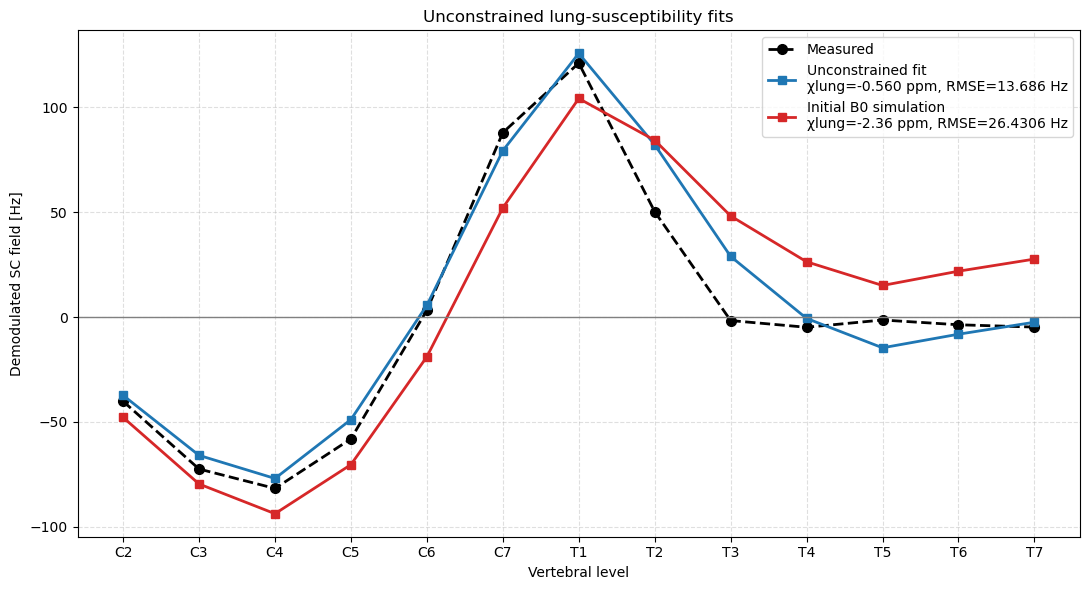

In [42]:
fig, ax = plt.subplots(figsize=(11, 6))

ax.plot(
    vertebrae_levels_opt,
    measured_profile,
    marker="o",
    markersize=7,
    linestyle="--",
    linewidth=2,
    color="black",
    label="Measured",
)

ax.plot(
    vertebrae_levels_opt,
    profile_unconstrained, #dmod_profile_unconstrained
    marker="s",
    markersize=6,
    linewidth=2,
    color="tab:blue",
    label=(
        "Unconstrained fit\n"
        f"χlung={chi_lung_unconstrained:.3f} ppm, "
        f"RMSE={rmse_unconstrained:.3f} Hz"
    ),
)

ax.plot(
    vertebrae_levels_opt,
    dmod_sim_metrics_data_Hz, #dmod_profile_unconstrained
    marker="s",
    markersize=6,
    linewidth=2,
    color="tab:red",
    label=(
        "Initial B0 simulation\n"
        f"χlung={-2.36} ppm, "
       f"RMSE={rmse_initial:.4f} Hz"
    ),
)


ax.axhline(
    0,
    color="gray",
    linewidth=1,
)

ax.set_xlabel("Vertebral level")
ax.set_ylabel("Demodulated SC field [Hz]")

ax.set_title(
    "Unconstrained "
    "lung-susceptibility fits"
)

ax.grid(
    True,
    linestyle="--",
    alpha=0.4,
)

ax.legend()

fig.tight_layout()
plt.show()

### Saving final fit


In [43]:
fit_results_df = pd.DataFrame({
    "VertebralLevel": vertebrae_levels_opt,
    "MeasuredProfile_Hz": measured_profile,
    "FittedProfile_Hz": profile_unconstrained,
    "Residual_Hz": residual_unconstrained,
})

fit_results_df["FittedLungChi_ppm"] = (
    chi_lung_unconstrained
)

fit_results_df["FitRMSE_Hz"] = (
    rmse_unconstrained
)

fit_results_df

,VertebralLevel,MeasuredProfile_Hz,FittedProfile_Hz,Residual_Hz,FittedLungChi_ppm,FitRMSE_Hz
0,C2,-40.210772,-37.382734,2.828038,-0.560096,13.686491
1,C3,-72.535960,-66.017052,6.518908,-0.560096,13.686491
2,C4,-81.800945,-77.050580,4.750365,-0.560096,13.686491
3,C5,-58.159866,-48.939544,9.220322,-0.560096,13.686491
4,C6,3.227148,5.594661,2.367513,-0.560096,13.686491
5,C7,87.990658,79.365293,-8.625365,-0.560096,13.686491
6,T1,121.149813,125.806553,4.656740,-0.560096,13.686491
7,T2,50.263994,82.198588,31.934594,-0.560096,13.686491
8,T3,-1.697960,28.898123,30.596083,-0.560096,13.686491
9,T4,-4.902405,-0.679962,4.222443,-0.560096,13.686491


In [44]:
fit_results_csv = (
    r"R:\soothsayer\msc_data\chi_fitting\chi_027\sub-16_lung_chi_avg_respiration_unconstrained_fit.csv"
)

fit_results_df.to_csv(
    fit_results_csv,
    index=False,
)

print(f"Saved fit results to:\n{fit_results_csv}")

Saved fit results to:
R:\soothsayer\msc_data\chi_fitting\chi_027\sub-16_lung_chi_avg_respiration_unconstrained_fit.csv


### Debug

In [52]:
selected_metric_mask = np.isin(
    metric_sim_mask,
    [
        vertebra_label_map[level]
        for level in vertebrae_levels_opt
    ],
)

print(
    "All simulation demodulation voxels:",
    np.count_nonzero(dmod_sim_mask == 1),
)

print(
    "Selected C2-T7 metric voxels:",
    np.count_nonzero(selected_metric_mask),
)

print(
    "Demodulation voxels outside C2-T7:",
    np.count_nonzero(
        (dmod_sim_mask == 1)
        & (~selected_metric_mask)
    ),
)

print(
    "Mean measured profile:",
    np.mean(measured_profile),
)

print(
    "Mean simulated fitted profile:",
    np.mean(profile_unconstrained),
)

print(
    "Mean residual:",
    np.mean(
        profile_unconstrained - measured_profile
    ),
)

All simulation demodulation voxels: 24855
Selected C2-T7 metric voxels: 12429
Demodulation voxels outside C2-T7: 12426
Mean measured profile: -0.0387564781503993
Mean simulated fitted profile: 5.107191003709157
Mean residual: 5.14594748185956


In [56]:
print(
    "Least-squares orthogonality:",
    np.dot(lung_response, residual_unconstrained)
)

Least-squares orthogonality: -3.019806626980426e-13


The closer it is to zero then it means the LS results is truly the LSQ minimum for the curred fixed_profile vs lung_response